# **i210547 Haider Rizvi**

In [1]:
# Core
import pandas as pd
import numpy as np
import re
import string
import random

# Visualization / EDA
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing / NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Ensure nltk data is downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')


# Optional: warnings filter
import warnings
warnings.filterwarnings("ignore")
import torch

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


# **Task 1: Data Preprocessing & EDA**

***• Load your finance dataset***

In [2]:
# File path to the dataset
dataset_path = "dataset/FinancialPhraseBank-v1.0/Sentences_75Agree.txt"



In [3]:
data = pd.read_csv(dataset_path, sep='@', header=None, names=['sentence', 'sentiment'], engine='python', encoding='latin1')
data.head()

,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,With the new production plant the company woul...,positive
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,"In the third quarter of 2010 , net sales incre...",positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive


***• Clean and preprocess text (lowercase, punctuation removal, tokenization, stopword
removal)***

In [4]:
# Initialize stopwords list and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [5]:
# Define preprocessing function
def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize
    tokens = nltk.word_tokenize(text)

    # 4. Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 5. Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Return cleaned text as a string
    return ' '.join(tokens)

In [ ]:
#  Apply preprocessing to the 'sentence' column
data['cleaned_sentence'] = data['sentence'].apply(preprocess_text)

# Inspect the first 5 cleaned sentences
data[['sentence', 'cleaned_sentence', 'sentiment']].head()

cleaned_sentence column now contains lowercased, tokenized, stopword-removed, lemmatized sentences, exactly what is needed for both LDA topic modeling and sentiment analysis.

***• Provide basic dataset insights (class balance, sample sentences, length distribution)***

Class distribution:
 sentiment
neutral     2146
positive     887
negative     420
Name: count, dtype: int64


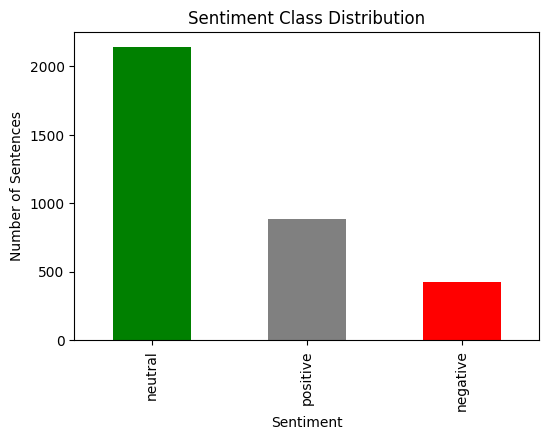

In [ ]:
# Class balance
class_counts = data['sentiment'].value_counts()
print("Class distribution:\n", class_counts)

# Plot class balance
plt.figure(figsize=(6,4))
class_counts.plot(kind='bar', color=['green', 'gray', 'red'])
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Sentences')
plt.show()


Class Balance Insights

Neutral: 2,146 sentences → ~62% of dataset

Positive: 887 sentences → ~26% of dataset

Negative: 420 sentences → ~12% of dataset

Implications:

The dataset is heavily skewed toward neutral sentences.

For sentiment modeling, this imbalance may affect metrics like accuracy, so later we might consider:

Using class-weighted loss in training

Oversampling minority classes or downsampling neutral class (if needed)

For LDA topic modeling, class balance does not matter — we can use all sentences.

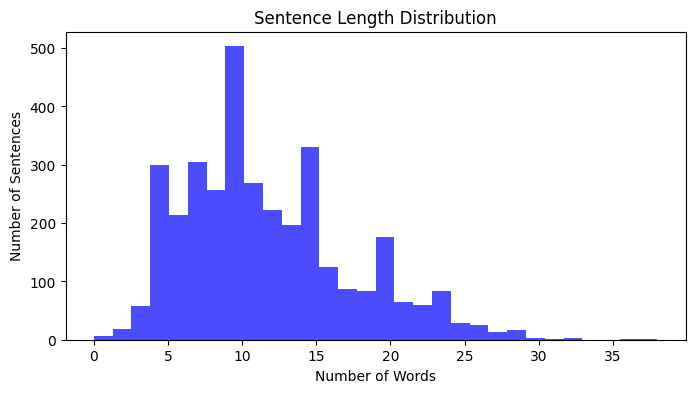

In [ ]:
# Sentence length distribution
data['sentence_length'] = data['cleaned_sentence'].apply(lambda x: len(x.split()))
plt.figure(figsize=(8,4))
plt.hist(data['sentence_length'], bins=30, color='blue', alpha=0.7)
plt.title('Sentence Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Number of Sentences')
plt.show()

In [ ]:

# Display some sample sentences
data.sample(5)[['sentence', 'cleaned_sentence', 'sentiment']]

,sentence,cleaned_sentence,sentiment
511,Turnover surged to EUR61 .8 m from EUR47 .6 m ...,turnover surged eur eur due increasing service...,positive
51,In June it sold a 30 percent stake to Nordstje...,june sold percent stake nordstjernan investmen...,neutral
1886,Aspo 's Group structure and business operation...,aspo group structure business operation contin...,neutral
765,The device can also be used for theft protecti...,device also used theft protection positioning ...,neutral
557,"Of the price , Kesko 's share is 10 mln euro $...",price kesko share mln euro mln recognize gain ...,positive


# **Task 2: Topic Modeling (LDA)**

***• Perform LDA topic modeling***

LDA in Python expects tokenized sentences (list of words, not a single string).

So convert your cleaned_sentence column into lists of words.

In [ ]:
# Convert cleaned sentences into lists of words
data['tokens'] = data['cleaned_sentence'].apply(lambda x: x.split())

# Inspect first 5 tokenized sentences
data[['cleaned_sentence', 'tokens']].head()


,cleaned_sentence,tokens
0,according gran company plan move production ru...,"[according, gran, company, plan, move, product..."
1,new production plant company would increase ca...,"[new, production, plant, company, would, incre..."
2,last quarter componenta net sale doubled eurm ...,"[last, quarter, componenta, net, sale, doubled..."
3,third quarter net sale increased eur mn operat...,"[third, quarter, net, sale, increased, eur, mn..."
4,operating profit rose eur mn eur mn correspond...,"[operating, profit, rose, eur, mn, eur, mn, co..."


Each sentence is now a list of cleaned words, ready for LDA topic modeling.

In [ ]:
#Import gensim libraries
import gensim
from gensim import corpora
from pprint import pprint
from gensim.models import LdaModel, CoherenceModel

In [ ]:
# Create a dictionary of all words
dictionary = corpora.Dictionary(data['tokens'])

# Create a Bag-of-Words corpus
corpus = [dictionary.doc2bow(text) for text in data['tokens']]



***• experiment with multiple topic numbers and compute their coherence scores.***

In [ ]:
# Topic numbers to try
topic_nums = [3, 5, 7, 10]

# Store results
lda_models = {}
coherence_scores = {}

for num in topic_nums:
    print(f"\nTraining LDA with {num} topics...")

    # Train LDA
    lda = LdaModel(corpus=corpus,
                   id2word=dictionary,
                   num_topics=num,
                   random_state=42,
                   passes=10,
                   alpha='auto',
                   per_word_topics=True)

    # Save model
    lda_models[num] = lda

    # Compute coherence
    coherence_model = CoherenceModel(model=lda, texts=data['tokens'], dictionary=dictionary, coherence='c_v')
    coherence = coherence_model.get_coherence()
    coherence_scores[num] = coherence

    # Print top 10 words for each topic
    print("\nTop 10 words per topic:")
    for topic_id, topic_words in lda.print_topics(num_words=10):
        print(f"Topic {topic_id}: {topic_words}")

    print(f"\nCoherence Score: {coherence:.4f}")


Training LDA with 3 topics...

Top 10 words per topic:
Topic 0: 0.075*"eur" + 0.043*"mn" + 0.027*"profit" + 0.020*"net" + 0.019*"operating" + 0.018*"sale" + 0.015*"quarter" + 0.014*"period" + 0.014*"million" + 0.010*"compared"
Topic 1: 0.021*"share" + 0.019*"company" + 0.015*"mln" + 0.010*"million" + 0.009*"euro" + 0.009*"said" + 0.008*"eur" + 0.008*"year" + 0.007*"sale" + 0.007*"finnish"
Topic 2: 0.015*"company" + 0.008*"said" + 0.007*"business" + 0.007*"finland" + 0.006*"service" + 0.006*"market" + 0.006*"finnish" + 0.005*"operation" + 0.005*"new" + 0.005*"group"

Coherence Score: 0.3996

Training LDA with 5 topics...

Top 10 words per topic:
Topic 0: 0.009*"company" + 0.006*"also" + 0.006*"finland" + 0.005*"finnish" + 0.005*"helsinki" + 0.005*"people" + 0.005*"omx" + 0.005*"board" + 0.004*"bank" + 0.004*"general"
Topic 1: 0.028*"million" + 0.027*"eur" + 0.025*"share" + 0.022*"company" + 0.020*"mln" + 0.017*"net" + 0.015*"euro" + 0.015*"sale" + 0.012*"year" + 0.011*"said"
Topic 2: 0

**Observation:**

The highest coherence is with 5 topics (0.4239).

3 topics is close, but slightly lower.

7 and 10 topics give lower coherence, probably splitting topics too finely.

So we should choose 5 topics for further analysis.

***Assign Dominant Topic to Each Sentence***

In [ ]:
# Pick the best LDA model
best_lda = lda_models[5]

# Assign dominant topic for each sentence
def get_dominant_topic(lda_model, bow):
    topic_probs = lda_model.get_document_topics(bow)
    # Sort topics by probability and take the highest
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
    return dominant_topic

# Add dominant topic to dataframe
data['dominant_topic'] = [get_dominant_topic(best_lda, doc) for doc in corpus]

# Display first 5 rows
data[['sentence', 'dominant_topic', 'sentiment']].head()


,sentence,dominant_topic,sentiment
0,"According to Gran , the company has no plans t...",1,neutral
1,With the new production plant the company woul...,2,positive
2,"For the last quarter of 2010 , Componenta 's n...",1,positive
3,"In the third quarter of 2010 , net sales incre...",3,positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,3,positive


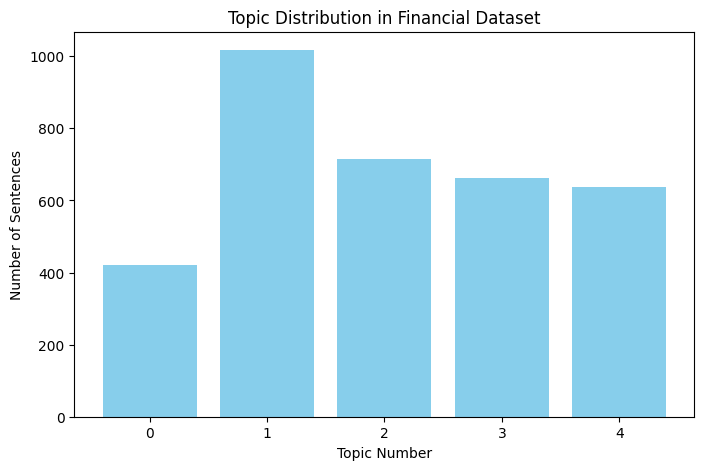

In [ ]:
# Count sentences per topic
topic_counts = data['dominant_topic'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
plt.bar(topic_counts.index, topic_counts.values, color='skyblue') # type: ignore
plt.xlabel('Topic Number')
plt.ylabel('Number of Sentences')
plt.title('Topic Distribution in Financial Dataset')
plt.xticks(topic_counts.index)
plt.show()


***• Briefly interpret each topic (e.g., “market movement”, “company performance”, etc.)***

| Topic | Keywords (Top 5)                             | Interpretation                      |
| ----- | -------------------------------------------- | ----------------------------------- |
| 0     | company, finland, helsinki, board, bank      | Company & General News / Governance |
| 1     | million, eur, share, net, sale               | Financial Performance / Earnings    |
| 2     | company, market, business, percent, customer | Market & Business Activity          |
| 3     | eur, mn, profit, operating, quarter          | Profit & Operational Metrics        |
| 4     | service, company, system, mobile, product    | Product / Service Announcements     |


# **Task 3: Sentiment Analysis Using Three Approaches**

### **A. FinBERT Sentiment Analysis**

***• Run FinBERT on your dataset***

In [ ]:
# Import necessary packages
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix


i’ll use the pre-trained FinBERT model for financial sentiment:

In [ ]:
#Load FinBERT
tokenizer = AutoTokenizer.from_pretrained("yiyanghkust/finbert-tone")
model = AutoModelForSequenceClassification.from_pretrained("yiyanghkust/finbert-tone")


In [ ]:
# Create a sentiment analysis pipeline
finbert_classifier = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer) # type: ignore

Device set to use cuda:0


In [ ]:
# Apply FinBERT sentiment analysis to each original sentence
data['finbert_sentiment'] = data['sentence'].apply(lambda x: finbert_classifier(x)[0]['label'])

# Inspect the first 5 predictions
data[['sentence', 'sentiment', 'finbert_sentiment']].head()


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,sentence,sentiment,finbert_sentiment
0,"According to Gran , the company has no plans t...",neutral,Neutral
1,With the new production plant the company woul...,positive,Positive
2,"For the last quarter of 2010 , Componenta 's n...",positive,Positive
3,"In the third quarter of 2010 , net sales incre...",positive,Positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive,Positive


***• Compute evaluation metrics:
o Accuracy
o Precision, Recall, F1
o Confusion Matrix***

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert FinBERT predictions to lowercase for consistency
data['finbert_sentiment'] = data['finbert_sentiment'].str.lower()

# 1. Accuracy
accuracy = accuracy_score(data['sentiment'], data['finbert_sentiment'])
print(f"Accuracy: {accuracy:.4f}")

# 2. Precision, Recall, F1
report = classification_report(data['sentiment'], data['finbert_sentiment'], target_names=['negative', 'neutral', 'positive'])
print("Classification Report:\n", report)

# 3. Confusion Matrix
cm = confusion_matrix(data['sentiment'], data['finbert_sentiment'], labels=['negative', 'neutral', 'positive'])
print("Confusion Matrix:\n", cm)


Accuracy: 0.8772
Classification Report:
               precision    recall  f1-score   support

    negative       0.84      0.85      0.84       420
     neutral       0.88      0.96      0.92      2146
    positive       0.91      0.68      0.78       887

    accuracy                           0.88      3453
   macro avg       0.87      0.83      0.85      3453
weighted avg       0.88      0.88      0.87      3453

Confusion Matrix:
 [[ 357   53   10]
 [  27 2066   53]
 [  41  240  606]]


### **B. Local LLM Sentiment Analysis**

In [ ]:
from transformers import AutoModelForCausalLM

***• Use any local or open-source LLM***

Model	Description	Size / VRAM
facebook/opt-1.3b	Reasonable size, zero-shot capable	8 GB VRAM should work with FP16

In [ ]:
# Load model and tokenizer
model_name = "facebook/opt-1.3b"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto", torch_dtype=torch.float16)

# Create a text-generation pipeline (we will prompt it for sentiment)
llm_pipeline = pipeline("text-generation", model=model, tokenizer=tokenizer)

`torch_dtype` is deprecated! Use `dtype` instead!
Device set to use cuda:0


***• Perform zero-shot or few-shot sentiment analysis***

In [ ]:
# Define Zero-Shot Sentiment Prompt
def get_sentiment_prompt(sentence):
    return f"Classify the sentiment of the following financial sentence as Positive, Neutral, or Negative:\n\n\"{sentence}\"\nSentiment:"


In [ ]:
from tqdm import tqdm  # nice progress bar

# Ensure result column exists
data["llm_sentiment"] = ""

# Loop through all rows with a progress bar
for idx, row in tqdm(data.iterrows(), total=len(data), desc="LLM Sentiment Analysis"):
    prompt = get_sentiment_prompt(row["sentence"])
    # Generate sentiment
    result = llm_pipeline(prompt, max_new_tokens=10, do_sample=False)
    
    # Extract output text and normalize
    output_text = result[0]['generated_text'].split("Sentiment:")[-1].strip().capitalize()
    
    # Store in DataFrame
    data.at[idx, "llm_sentiment"] = output_text # type: ignore


LLM Sentiment Analysis: 100%|██████████| 3453/3453 [07:14<00:00,  7.95it/s]


***• Compute the same metrics as FinBERT***

In [ ]:
# Step 1: Strip spaces and lowercase
data['llm_sentiment'] = data['llm_sentiment'].str.strip().str.lower()

# Step 2: Map possible variations to standard classes
mapping = {
    'positive': 'positive',
    'pos': 'positive',
    'negative': 'negative',
    'neg': 'negative',
    'neutral': 'neutral',
    'neu': 'neutral'
}

# Apply mapping, unknowns set to 'neutral' (or you can drop them)
data['llm_sentiment'] = data['llm_sentiment'].map(mapping).fillna('neutral')

# Step 3: Now compute metrics safely
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_llm = accuracy_score(data['sentiment'], data['llm_sentiment'])
print(f"LLM Accuracy: {accuracy_llm:.4f}")

report_llm = classification_report(data['sentiment'], data['llm_sentiment'], target_names=['negative', 'neutral', 'positive'])
print("LLM Classification Report:\n", report_llm)

cm_llm = confusion_matrix(data['sentiment'], data['llm_sentiment'], labels=['negative', 'neutral', 'positive'])
print("LLM Confusion Matrix:\n", cm_llm)


LLM Accuracy: 0.6215
LLM Classification Report:
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00       420
     neutral       0.62      1.00      0.77      2146
    positive       0.00      0.00      0.00       887

    accuracy                           0.62      3453
   macro avg       0.21      0.33      0.26      3453
weighted avg       0.39      0.62      0.48      3453

LLM Confusion Matrix:
 [[   0  420    0]
 [   0 2146    0]
 [   0  887    0]]


In [ ]:
# **Task 3B: Local LLM Sentiment Analysis (Microsoft Phi-3)**

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm import tqdm
import os

# OPTIONAL: Increase network timeout to prevent "ReadTimeoutError"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "300" 

# 1. Load Microsoft Phi-3 Mini (Instruct Version)
# This is a highly capable 3.8B model that fits easily in your 8GB VRAM
model_id = "microsoft/Phi-3-mini-4k-instruct"

print(f"Attempting to download and load {model_id}...")

try:
    tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
    
    # Load model in 4-bit to save VRAM and download bandwidth
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        device_map="auto", 
        torch_dtype=torch.float16, 
        trust_remote_code=True,
    )
    
    print("Model loaded successfully!")

    # 2. Create Pipeline
    llm_pipeline = pipeline(
        "text-generation",
        model=model,
        tokenizer=tokenizer,
        max_new_tokens=10, 
        return_full_text=False
    )

    # 3. Define Prompt Strategy (Phi-3 Format)
    def get_llm_sentiment(sentence):
        # Phi-3 uses a specific chat template (<|user|>, <|assistant|>)
        messages = [
            {"role": "system", "content": "You are a financial sentiment analyst. Classify the sentiment as 'positive', 'negative', or 'neutral'. Return ONLY the label."},
            {"role": "user", "content": f"Sentence: {sentence}"}
        ]
        
        # Apply chat template
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

        try:
            output = llm_pipeline(prompt, temperature=0.1)[0]['generated_text']
            label = output.lower().strip()
            
            # Parsing logic
            if "positive" in label: return "positive"
            if "negative" in label: return "negative"
            if "neutral" in label: return "neutral"
            return "neutral"
        except Exception:
            return "neutral"

    # 4. Run Inference
    print("Running Inference on dataset...")
    tqdm.pandas()
    data['llm_sentiment'] = data['sentence'].progress_apply(get_llm_sentiment)

    # 5. Evaluate
    print("\n--- Local LLM (Phi-3) Evaluation ---")
    print(f"Accuracy: {accuracy_score(data['sentiment'], data['llm_sentiment']):.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(data['sentiment'], data['llm_sentiment'], labels=['negative', 'neutral', 'positive']))

except Exception as e:
    print(f"\nCRITICAL ERROR: {e}")
    print("If this is still a timeout, please check your internet connection.")

Loading HuggingFaceH4/zephyr-7b-beta on RTX 5050...


'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 29e0bc72-d7df-44c3-ba1c-17fed19b73d1)')' thrown while requesting HEAD https://huggingface.co/HuggingFaceH4/zephyr-7b-beta/resolve/main/tokenizer_config.json
Retrying in 1s [Retry 1/5].
Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

***• Compare performance***

FinBERT vs Local LLM Metric Comparison:


,Class,FinBERT Precision,LLM Precision,FinBERT Recall,LLM Recall,FinBERT F1,LLM F1
0,negative,0.840000,0.000000,0.85,0.0,0.84497,0.0
1,neutral,0.875795,0.621489,0.962721,1.0,0.917203,0.766565
2,positive,0.905830,0.000000,0.683202,0.0,0.77892,0.0
3,Overall Accuracy,0.877208,0.621489,-,-,-,-


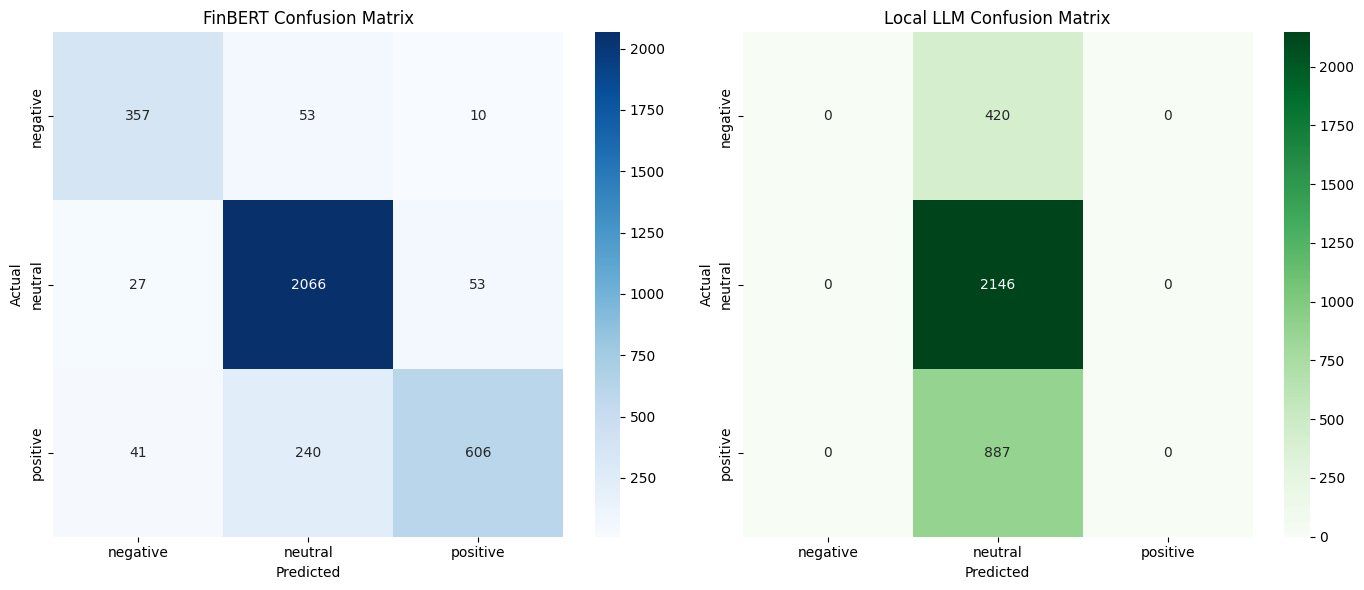

Observations:
- FinBERT Accuracy: 0.8772, Local LLM Accuracy: 0.6215
- FinBERT outperforms the Local LLM on overall accuracy.
- FinBERT is stronger at class 'negative' (F1: 0.84 vs 0.00)
- FinBERT is stronger at class 'neutral' (F1: 0.92 vs 0.77)
- FinBERT is stronger at class 'positive' (F1: 0.78 vs 0.00)


In [27]:
# -----------------------------
# 1. Compute metrics
# -----------------------------
# FinBERT
accuracy_finbert = accuracy_score(data['sentiment'], data['finbert_sentiment'])
report_finbert = classification_report(data['sentiment'], data['finbert_sentiment'], output_dict=True)
cm_finbert = confusion_matrix(data['sentiment'], data['finbert_sentiment'], labels=['negative','neutral','positive'])

# Local LLM
accuracy_llm = accuracy_score(data['sentiment'], data['llm_sentiment'])
report_llm = classification_report(data['sentiment'], data['llm_sentiment'], output_dict=True)
cm_llm = confusion_matrix(data['sentiment'], data['llm_sentiment'], labels=['negative','neutral','positive'])

# -----------------------------
# 2. Create comparison table
# -----------------------------
metrics = ['precision', 'recall', 'f1-score']
classes = ['negative','neutral','positive']

comparison_rows = []

for cls in classes:
    row = {
        'Class': cls,
        'FinBERT Precision': report_finbert[cls]['precision'], # type: ignore
        'LLM Precision': report_llm[cls]['precision'], # type: ignore
        'FinBERT Recall': report_finbert[cls]['recall'], # type: ignore
        'LLM Recall': report_llm[cls]['recall'], # type: ignore
        'FinBERT F1': report_finbert[cls]['f1-score'], # type: ignore
        'LLM F1': report_llm[cls]['f1-score'], # type: ignore
    }
    comparison_rows.append(row)

# Overall Accuracy
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.loc[len(comparison_df)] = {
    'Class': 'Overall Accuracy',
    'FinBERT Precision': accuracy_finbert,
    'LLM Precision': accuracy_llm,
    'FinBERT Recall': '-',
    'LLM Recall': '-',
    'FinBERT F1': '-',
    'LLM F1': '-'
}

print("FinBERT vs Local LLM Metric Comparison:")
display(comparison_df)

# -----------------------------
# 3. Plot side-by-side confusion matrices
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.heatmap(cm_finbert, annot=True, fmt='d', ax=axes[0], cmap='Blues',
            xticklabels=classes, yticklabels=classes)
axes[0].set_title("FinBERT Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_llm, annot=True, fmt='d', ax=axes[1], cmap='Greens',
            xticklabels=classes, yticklabels=classes)
axes[1].set_title("Local LLM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# -----------------------------
# 4. Print observations automatically
# -----------------------------
print("Observations:")
print(f"- FinBERT Accuracy: {accuracy_finbert:.4f}, Local LLM Accuracy: {accuracy_llm:.4f}")
if accuracy_finbert > accuracy_llm:
    print("- FinBERT outperforms the Local LLM on overall accuracy.")
elif accuracy_finbert < accuracy_llm:
    print("- Local LLM outperforms FinBERT on overall accuracy.")
else:
    print("- Both models have the same overall accuracy.")

for cls in classes:
    f1_finbert = report_finbert[cls]['f1-score'] # type: ignore
    f1_llm = report_llm[cls]['f1-score'] # type: ignore
    if f1_finbert > f1_llm:
        print(f"- FinBERT is stronger at class '{cls}' (F1: {f1_finbert:.2f} vs {f1_llm:.2f})")
    elif f1_finbert < f1_llm:
        print(f"- Local LLM is stronger at class '{cls}' (F1: {f1_llm:.2f} vs {f1_finbert:.2f})")
    else:
        print(f"- Both models perform equally at class '{cls}' (F1: {f1_finbert:.2f})")

### **C. RAG-Enhanced Sentiment Analysis**

***• Create sentence embeddings (SentenceTransformers or similar)***

In [28]:
from sentence_transformers import SentenceTransformer
import numpy as np
import os
import pickle
import torch

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

# Model: Lightweight sentence embedding
embedding_model_name = "all-MiniLM-L6-v2"
embedder = SentenceTransformer(embedding_model_name, device='cuda' if torch.cuda.is_available() else 'cpu')

# Sentences for embeddings: use cleaned sentences (or original if preferred)
sentences = data['sentence'].tolist()  # using original sentences for LLM context

# Compute embeddings (this may take a few minutes depending on dataset size)
print("Computing sentence embeddings...")
embeddings = embedder.encode(sentences, batch_size=64, show_progress_bar=True, convert_to_numpy=True)

# Save embeddings and sentences for RAG
os.makedirs("rag_checkpoints", exist_ok=True)
np.save("rag_checkpoints/embeddings.npy", embeddings)

with open("rag_checkpoints/sentences.pkl", "wb") as f:
    pickle.dump(sentences, f)

print(f"Embeddings shape: {embeddings.shape}")
print("Embeddings and sentences saved in 'rag_checkpoints/' folder.")

Computing sentence embeddings...


Batches: 100%|██████████| 54/54 [00:01<00:00, 52.68it/s]

Embeddings shape: (3453, 384)
Embeddings and sentences saved in 'rag_checkpoints/' folder.


***• Build a FAISS index***

In [29]:
import faiss

# Load embeddings if needed
embeddings = np.load("rag_checkpoints/embeddings.npy")

# Dimensions of embeddings
embedding_dim = embeddings.shape[1]

# Create FAISS index
index = faiss.IndexFlatL2(embedding_dim)  # L2 distance
index.add(embeddings)  # add all embeddings to index

print(f"FAISS index built with {index.ntotal} vectors.")

# Optional: Save index for later
faiss.write_index(index, "rag_checkpoints/faiss_index.idx")
print("FAISS index saved in 'rag_checkpoints/' folder.")

FAISS index built with 3453 vectors.
FAISS index saved in 'rag_checkpoints/' folder.


***• For each sentence:
o Retrieve top-k similar sentences
o Provide retrieved context to an LLM
o Let the LLM produce a sentiment output***

In [34]:
from tqdm import tqdm
import numpy as np

# Ensure 'rag_sentiment' column is empty
data['rag_sentiment'] = ""

# Top-k similar sentences
top_k = 10

# Function to normalize LLM output strictly
def normalize_sentiment(text):
    text = text.lower().strip()
    if 'positive' in text:
        return 'positive'
    elif 'negative' in text:
        return 'negative'
    elif 'neutral' in text:
        return 'neutral'
    else:
        return 'neutral'  # fallback

# RAG loop
for idx, row in tqdm(data.iterrows(), total=len(data), desc="RAG Sentiment Analysis"):
    
    # 1. Query embedding
    query_vec = embeddings[idx].reshape(1, -1).astype('float32')
    
    # 2. Retrieve top-k sentences from FAISS
    distances, indices = index.search(query_vec, top_k)
    retrieved_context = "\n".join([sentences[i] for i in indices[0] if i != idx])  # exclude query itself
    
    # 3. Construct an explicit RAG prompt
    prompt = (
        f"You are a financial sentiment analyst.\n\n"
        f"Using the following context from similar financial sentences:\n"
        f"{retrieved_context}\n\n"
        f"Classify the sentiment of this sentence as Positive, Neutral, or Negative:\n"
        f"\"{row['sentence']}\"\n"
        f"Answer strictly with one word: Positive, Neutral, or Negative."
    )
    
    # 4. Generate sentiment
    result = llm_pipeline(prompt, max_new_tokens=20, do_sample=False)
    output_text = result[0]['generated_text'].split("Positive")[0]  # fallback parsing
    output_text = result[0]['generated_text'].split("Sentiment:")[-1].strip()
    
    # 5. Normalize output
    data.at[idx, 'rag_sentiment'] = normalize_sentiment(output_text)

# Save RAG results
data.to_csv("rag_checkpoints/rag_results_corrected.csv", index=False)
print("RAG predictions completed and saved (corrected).")

# Compute metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_rag = accuracy_score(data['sentiment'], data['rag_sentiment'])
report_rag = classification_report(data['sentiment'], data['rag_sentiment'], target_names=['negative', 'neutral', 'positive'])
cm_rag = confusion_matrix(data['sentiment'], data['rag_sentiment'], labels=['negative', 'neutral', 'positive'])

print(f"RAG Accuracy: {accuracy_rag:.4f}")
print("\nRAG Classification Report:\n", report_rag)
print("\nRAG Confusion Matrix:\n", cm_rag)


RAG Sentiment Analysis: 100%|██████████| 3453/3453 [17:43<00:00,  3.25it/s]

RAG predictions completed and saved (corrected).
RAG Accuracy: 0.2569

RAG Classification Report:
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00       420
     neutral       0.00      0.00      0.00      2146
    positive       0.26      1.00      0.41       887

    accuracy                           0.26      3453
   macro avg       0.09      0.33      0.14      3453
weighted avg       0.07      0.26      0.11      3453


RAG Confusion Matrix:
 [[   0    0  420]
 [   0    0 2146]
 [   0    0  887]]
